# 03 - Baseline classiche

In questo notebook costruisco i modelli di base da confrontare più avanti con la CNN (RQ1). L'autore del dataset ha ottenuto un F1 di circa 0.98-0.99 con PCA + SVM, quindi provo a replicare anche io questo risultato.

Passi:
1. carico i dati e preparo le feature (grigio, 75x50, appiattite);
2. PCA calcolata solo sul train;
3. regressione logistica, k-NN e SVM con RBF, con tuning sul validation;
4. valutazione sul test (una sola volta) e analisi degli errori;
5. esperimento sul leakage: quanto si gonfia il punteggio con uno split casuale rispetto allo split per gruppi di duplicati.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 42
CLASSES = ['paper', 'rock', 'scissors']
FIG_DIR = '../results/figures'
MET_DIR = '../results/metrics'

## 1. Caricamento dei dati

In [2]:
d = np.load('../data.nosync/processed/rps_150x100.npz')
X_train, y_train = d['X_train'], d['y_train']
X_val, y_val = d['X_val'], d['y_val']
X_test, y_test = d['X_test'], d['y_test']
df = pd.read_csv('../splits/split.csv')

print(X_train.shape, X_val.shape, X_test.shape)
print(df['split'].value_counts())

(1536, 100, 150, 3) (326, 100, 150, 3) (326, 100, 150, 3)
split
train    1536
test      326
val       326
Name: count, dtype: int64


Gli array del file npz sono costruiti seguendo l'ordine delle righe di `split.csv`. Per l'esperimento sul leakage mi serve un array unico con tutte le immagini nello stesso ordine di `split.csv`, quindi lo ricostruisco e controllo che le etichette coincidano.

In [3]:
split = df['split'].to_numpy()
labels = np.array(df['label'].tolist())

# ricostruisco l'array completo nell'ordine di split.csv
X_all = np.zeros((len(df), 100, 150, 3), dtype=np.uint8)
X_all[np.where(split == 'train')[0]] = X_train
X_all[np.where(split == 'val')[0]] = X_val
X_all[np.where(split == 'test')[0]] = X_test

# controllo: le etichette numeriche corrispondono a quelle del csv
y_all = np.array([CLASSES.index(c) for c in labels])
print((y_all[split == 'train'] == y_train).all(), (y_all[split == 'val'] == y_val).all(), (y_all[split == 'test'] == y_test).all())

True True True


## 2. Feature per i modelli classici

Converto in scala di grigi con i pesi standard (0.299 R + 0.587 G + 0.114 B), riduco a 75x50 facendo la media di blocchi 2x2, divido per 255 e appiattisco: 3750 feature per immagine.

In [4]:
def estrai_feature(X):
    # grigio con i pesi standard
    grigio = X[:, :, :, 0] * 0.299 + X[:, :, :, 1] * 0.587 + X[:, :, :, 2] * 0.114
    # downscale 2x2: (N, 100, 150) -> (N, 50, 2, 75, 2), poi media sugli assi dei blocchi
    piccolo = grigio.reshape(len(X), 50, 2, 75, 2).mean(axis=(2, 4))
    return piccolo.reshape(len(X), -1) / 255.0

F_train = estrai_feature(X_train)
F_val = estrai_feature(X_val)
F_test = estrai_feature(X_test)
F_all = estrai_feature(X_all)
print(F_train.shape, F_val.shape, F_test.shape, F_all.shape)

(1536, 3750) (326, 3750) (326, 3750) (2188, 3750)


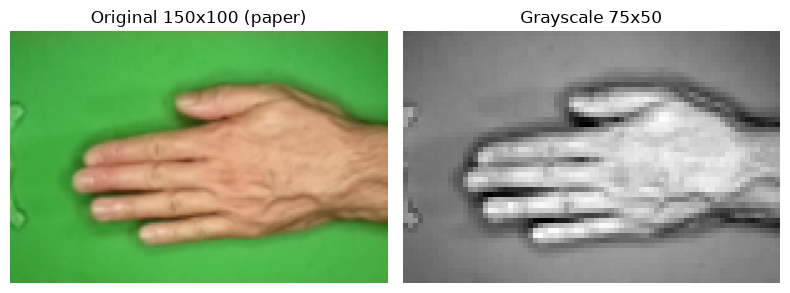

In [5]:
i = 0
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].imshow(X_train[i])
ax[0].set_title('Original 150x100 (' + CLASSES[y_train[i]] + ')')
ax[1].imshow(F_train[i].reshape(50, 75), cmap='gray')
ax[1].set_title('Grayscale 75x50')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR + '/baseline_features_example.png', dpi=150)
plt.show()

## 3. PCA

La PCA la calcolo **solo sul train**: se la facessi su tutti i dati, le componenti conterrebbero informazione di validation e test (leakage). Poi applico la stessa trasformazione a validation e test.

Calcolo una sola volta 200 componenti. Le componenti sono ordinate per varianza e non dipendono da quante ne tengo, quindi per usare n componenti basta prendere le prime n colonne dei dati trasformati: è equivalente a rifare la PCA con n_components=n.

In [6]:
pca = PCA(n_components=200, svd_solver='full', random_state=SEED)
pca.fit(F_train)
Z_train = pca.transform(F_train)
Z_val = pca.transform(F_val)
Z_test = pca.transform(F_test)

var_cum = np.cumsum(pca.explained_variance_ratio_)
for n in [20, 50, 100, 200]:
    print(n, 'componenti -> varianza spiegata', round(var_cum[n - 1], 4))

20 componenti -> varianza spiegata 0.7303
50 componenti -> varianza spiegata 0.8489
100 componenti -> varianza spiegata 0.9151
200 componenti -> varianza spiegata 0.9595


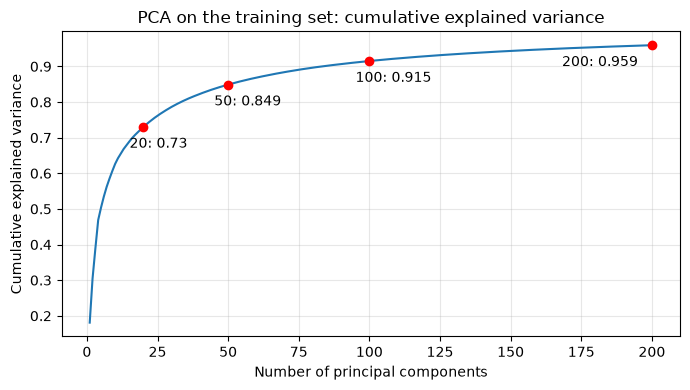

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, 201), var_cum)
for n in [20, 50, 100, 200]:
    plt.scatter(n, var_cum[n - 1], color='red', zorder=3)
    plt.annotate(str(n) + ': ' + str(round(var_cum[n - 1], 3)), (n, var_cum[n - 1]), textcoords='offset points', xytext=(-10, -15), ha='right' if n == 200 else 'left')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA on the training set: cumulative explained variance')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR + '/baseline_pca_variance.png', dpi=150)
plt.show()

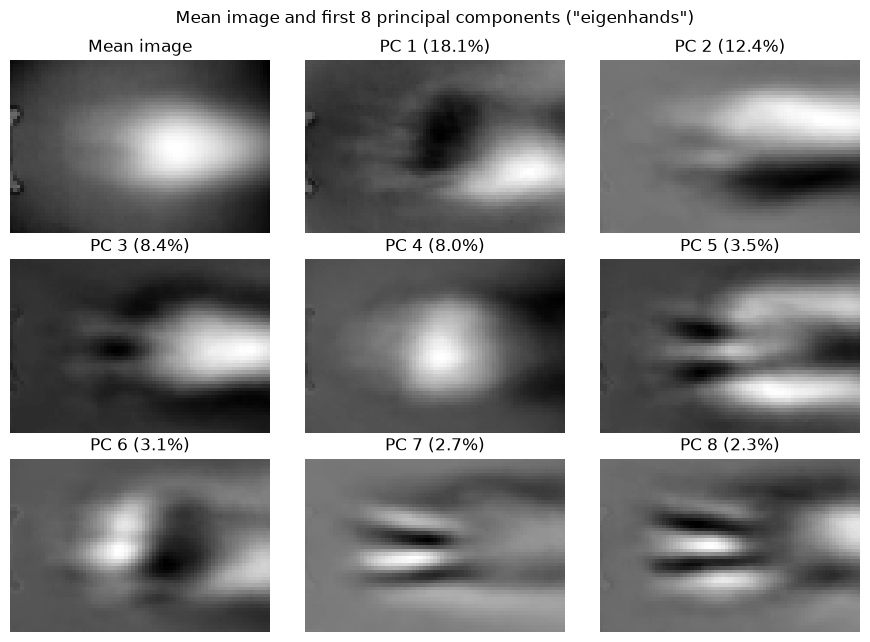

In [8]:
fig, ax = plt.subplots(3, 3, figsize=(9, 6.5))
ax = ax.ravel()
ax[0].imshow(pca.mean_.reshape(50, 75), cmap='gray')
ax[0].set_title('Mean image')
for j in range(8):
    ax[j + 1].imshow(pca.components_[j].reshape(50, 75), cmap='gray')
    ax[j + 1].set_title('PC ' + str(j + 1) + ' (' + str(round(100 * pca.explained_variance_ratio_[j], 1)) + '%)')
for a in ax:
    a.axis('off')
plt.suptitle('Mean image and first 8 principal components ("eigenhands")')
plt.tight_layout()
plt.savefig(FIG_DIR + '/baseline_pca_components.png', dpi=150)
plt.show()

## 4. Riferimento: classificatore banale

In [9]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(Z_train, y_train)
p = dummy.predict(Z_val)
dummy_val_acc = accuracy_score(y_val, p)
dummy_val_f1 = f1_score(y_val, p, average='macro')
print('Dummy validation: accuracy', round(dummy_val_acc, 4), '- macro-F1', round(dummy_val_f1, 4))

Dummy validation: accuracy 0.3436 - macro-F1 0.1705


## 5. Tuning sul validation

Per ogni modello fitto sul train e valuto sul validation con il macro-F1 (salvo anche l'accuracy). Uso dei cicli for espliciti sugli iperparametri. Il test non lo tocco.

In [10]:
def crea_modello(nome, valore):
    if nome == 'LogReg':
        return LogisticRegression(C=valore, max_iter=5000)
    if nome == 'kNN':
        return KNeighborsClassifier(n_neighbors=valore)
    if nome == 'SVM':
        return SVC(kernel='rbf', C=valore, gamma='scale')

griglie = {
    'LogReg': ('C', [20, 50, 100, 200], [0.01, 0.1, 1, 10]),
    'kNN': ('k', [20, 50, 100], [1, 3, 5, 7, 11, 15]),
    'SVM': ('C', [20, 50, 100], [1, 10, 100]),
}

righe = []
for nome in griglie:
    nome_param, lista_n, lista_val = griglie[nome]
    for n in lista_n:
        for v in lista_val:
            m = crea_modello(nome, v)
            m.fit(Z_train[:, :n], y_train)
            p = m.predict(Z_val[:, :n])
            righe.append([nome, n, nome_param, v, accuracy_score(y_val, p), f1_score(y_val, p, average='macro')])

val = pd.DataFrame(righe, columns=['model', 'n_components', 'param_name', 'param_value', 'val_accuracy', 'val_macro_f1'])
val['features'] = 'gray'
val.to_csv(MET_DIR + '/baseline_validation.csv', index=False)
print(len(val), 'configurazioni')
val.sort_values('val_macro_f1', ascending=False).head(10)

43 configurazioni


,model,n_components,param_name,param_value,val_accuracy,val_macro_f1,features
42,SVM,100,C,100.0,0.947853,0.947887,gray
41,SVM,100,C,10.0,0.947853,0.947887,gray
39,SVM,50,C,100.0,0.944785,0.944819,gray
38,SVM,50,C,10.0,0.938650,0.938665,gray
35,SVM,20,C,10.0,0.935583,0.935537,gray
36,SVM,20,C,100.0,0.932515,0.932453,gray
34,SVM,20,C,1.0,0.917178,0.916801,gray
28,kNN,100,k,1.0,0.914110,0.914411,gray
37,SVM,50,C,1.0,0.911043,0.910354,gray
40,SVM,100,C,1.0,0.907975,0.907304,gray


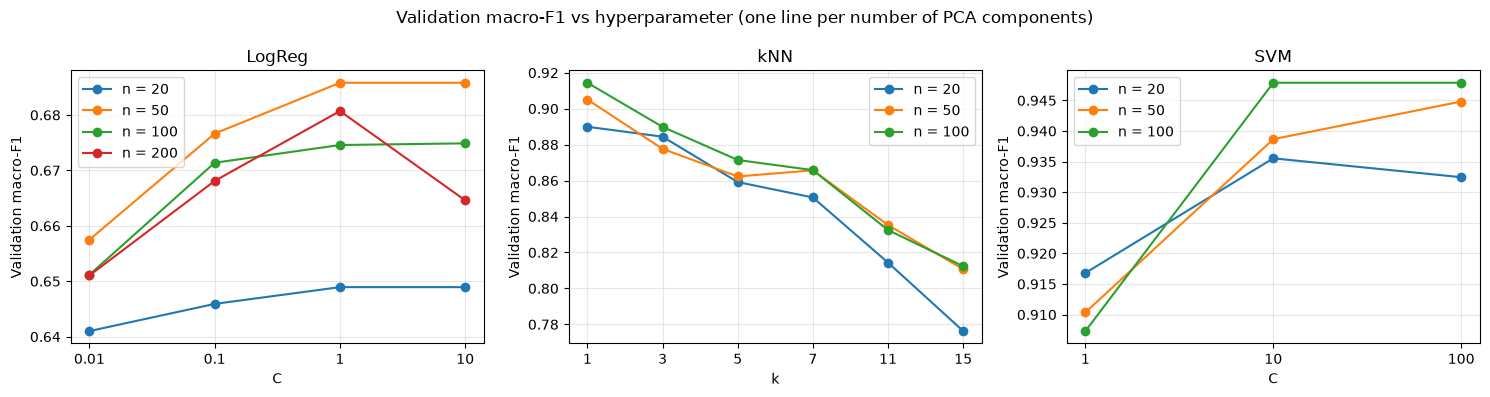

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j, nome in enumerate(griglie):
    nome_param, lista_n, lista_val = griglie[nome]
    for n in lista_n:
        sub = val[(val['model'] == nome) & (val['n_components'] == n)]
        ax[j].plot(range(len(lista_val)), sub['val_macro_f1'], marker='o', label='n = ' + str(n))
    ax[j].set_xticks(range(len(lista_val)))
    ax[j].set_xticklabels(lista_val)
    ax[j].set_xlabel(nome_param)
    ax[j].set_ylabel('Validation macro-F1')
    ax[j].set_title(nome)
    ax[j].grid(alpha=0.3)
    ax[j].legend()
plt.suptitle('Validation macro-F1 vs hyperparameter (one line per number of PCA components)')
plt.tight_layout()
plt.savefig(FIG_DIR + '/baseline_validation.png', dpi=150)
plt.show()

Scelgo la migliore configurazione per ogni modello col macro-F1 di validation. A parità vince quella più semplice: prima n più piccolo, poi il valore che compare prima nella lista. Siccome i cicli seguono questo ordine, basta aggiornare il migliore solo quando il punteggio è strettamente maggiore.

In [12]:
migliori = {}
for nome in griglie:
    sub = val[val['model'] == nome]
    best_f1 = -1
    for i in range(len(sub)):
        r = sub.iloc[i]
        if r['val_macro_f1'] > best_f1:
            best_f1 = r['val_macro_f1']
            v = r['param_value']
            if nome == 'kNN':
                v = int(v)  # nel csv la colonna e float perche mescola k (int) e C (float)
            migliori[nome] = (int(r['n_components']), v, r['val_accuracy'], r['val_macro_f1'])

for nome in migliori:
    n, v, acc, f1 = migliori[nome]
    print(nome, '-> n =', n, ',', griglie[nome][0], '=', v, '| val accuracy', round(acc, 4), '| val macro-F1', round(f1, 4))

LogReg -> n = 50 , C = 1.0 | val accuracy 0.6902 | val macro-F1 0.6858
kNN -> n = 100 , k = 1 | val accuracy 0.9141 | val macro-F1 0.9144
SVM -> n = 100 , C = 10.0 | val accuracy 0.9479 | val macro-F1 0.9479


## 6. Test (usato una volta sola)

Per la migliore configurazione di ogni modello fitto sul train e valuto sul test. Misuro anche il tempo di fit e il tempo di predizione per immagine.

In [13]:
def valuta_test(nome, modello, Ztr, Zte):
    t0 = time.time()
    modello.fit(Ztr, y_train)
    t_fit = time.time() - t0
    t0 = time.time()
    p = modello.predict(Zte)
    t_pred = (time.time() - t0) / len(Zte) * 1000
    return p, [nome, accuracy_score(y_test, p), f1_score(y_test, p, average='macro'), t_fit, t_pred]

righe_test = []
pred_test = {}

p, r = valuta_test('Dummy', DummyClassifier(strategy='most_frequent'), Z_train, Z_test)
righe_test.append(r + ['-', '-', '-'])
pred_test['Dummy'] = p

for nome in migliori:
    n, v = migliori[nome][0], migliori[nome][1]
    p, r = valuta_test(nome, crea_modello(nome, v), Z_train[:, :n], Z_test[:, :n])
    righe_test.append(r + [n, griglie[nome][0], v])
    pred_test[nome] = p

test = pd.DataFrame(righe_test, columns=['model', 'test_accuracy', 'test_macro_f1', 'fit_time_s', 'pred_time_ms_per_image', 'n_components', 'param_name', 'param_value'])
test['features'] = 'gray'
test.to_csv(MET_DIR + '/baseline_test.csv', index=False)
test

,model,test_accuracy,test_macro_f1,fit_time_s,pred_time_ms_per_image,n_components,param_name,param_value,features
0,Dummy,0.343558,0.170472,0.000241,0.000108,-,-,-,gray
1,LogReg,0.680982,0.681525,0.005510,0.000331,50,C,1.0,gray
2,kNN,0.892638,0.892815,0.000272,0.005297,100,k,1,gray
3,SVM,0.938650,0.938710,0.034952,0.038767,100,C,10.0,gray


In [14]:
# miglior modello: macro-F1 di validation piu alto (a parita il primo)
best_nome = None
best_f1 = -1
for nome in migliori:
    if migliori[nome][3] > best_f1:
        best_f1 = migliori[nome][3]
        best_nome = nome
print('Miglior modello (validation):', best_nome)

pred_best = pred_test[best_nome]
print(classification_report(y_test, pred_best, target_names=CLASSES, digits=4))

Miglior modello (validation): SVM
              precision    recall  f1-score   support

       paper     0.9412    0.9057    0.9231       106
        rock     0.9717    0.9537    0.9626       108
    scissors     0.9068    0.9554    0.9304       112

    accuracy                         0.9387       326
   macro avg     0.9399    0.9382    0.9387       326
weighted avg     0.9395    0.9387    0.9387       326



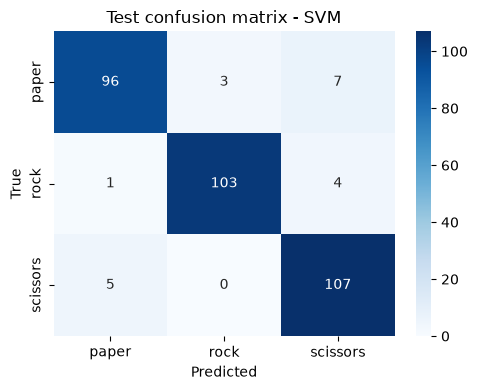

In [15]:
cm = confusion_matrix(y_test, pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test confusion matrix - ' + best_nome)
plt.tight_layout()
plt.savefig(FIG_DIR + '/baseline_confusion_matrix.png', dpi=150)
plt.show()

Immagini di test sbagliate: 20 su 326


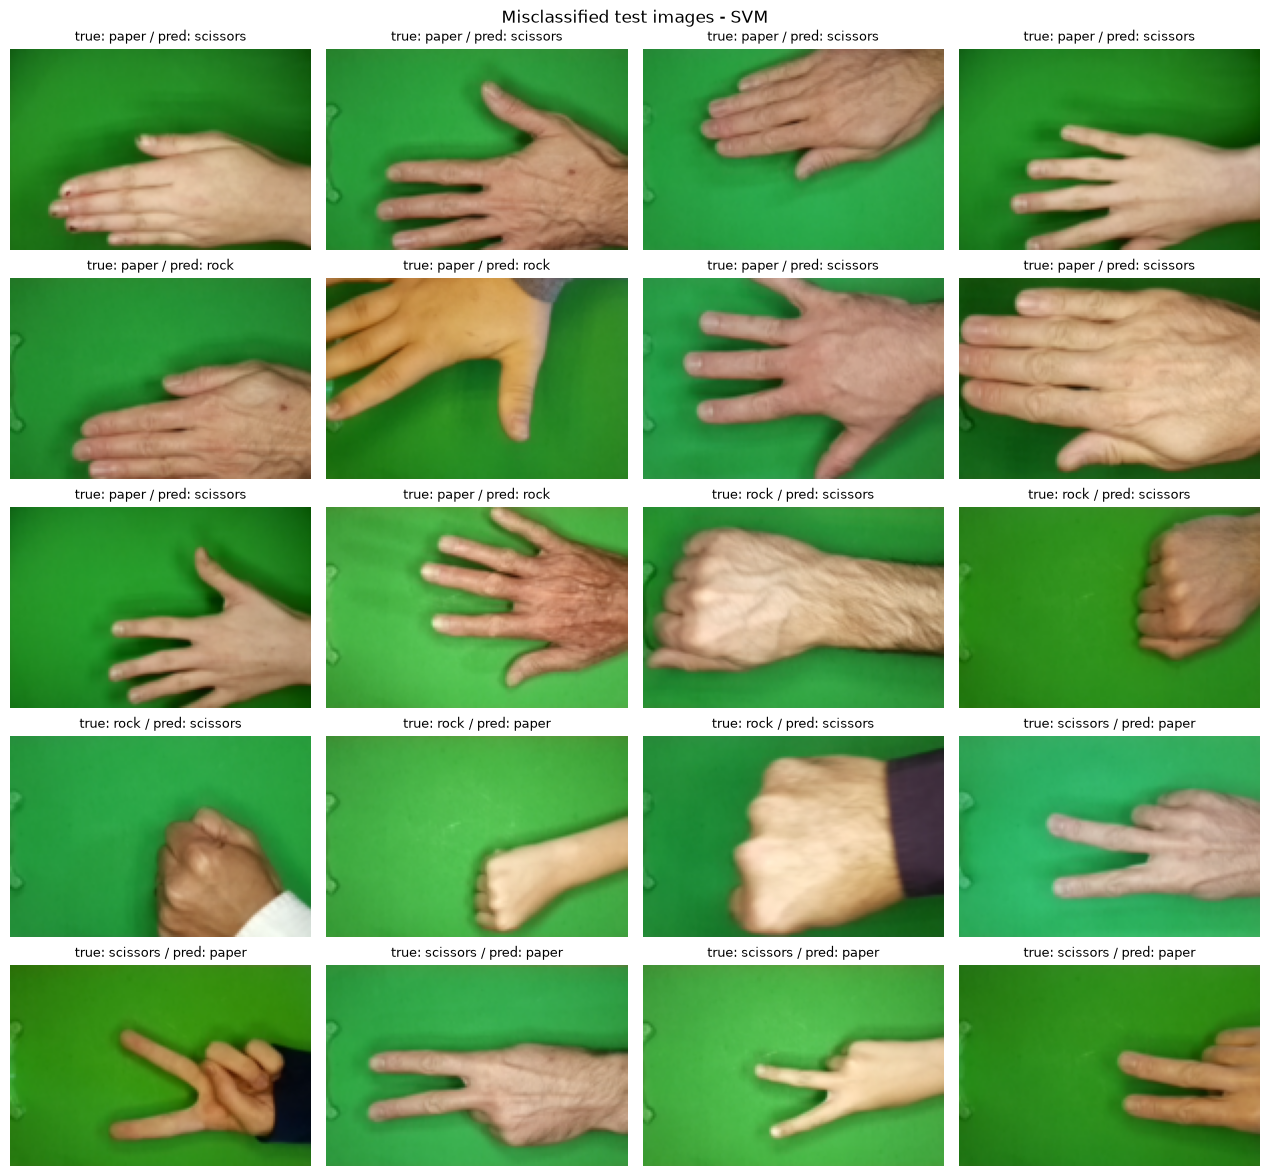

In [16]:
errori = np.where(pred_best != y_test)[0]
print('Immagini di test sbagliate:', len(errori), 'su', len(y_test))

if len(errori) == 0:
    print('Nessun errore sul test.')
else:
    ncol = 4
    nrow = int(np.ceil(len(errori) / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.4 * nrow))
    ax = np.array(ax).ravel()
    for a in ax:
        a.axis('off')
    for j, i in enumerate(errori):
        ax[j].imshow(X_test[i])
        ax[j].set_title('true: ' + CLASSES[y_test[i]] + ' / pred: ' + CLASSES[pred_best[i]], fontsize=9)
    plt.suptitle('Misclassified test images - ' + best_nome)
    plt.tight_layout()
    plt.savefig(FIG_DIR + '/baseline_errors.png', dpi=150)
    plt.show()

## 6b. Replica del metodo dell'autore: rimozione dello sfondo

Il punto 6 è sotto il 0.98-0.99 dichiarato dall'autore. Guardando il suo codice (repo `rps-cv`, file `rpscv/imgproc.py`, funzioni `getGray` e `removeBackground`) vedo che prima di PCA + SVM mette a nero lo sfondo verde. Replico questo passaggio.

Prima controllo però se il solo tuning di gamma dell'SVM sulle feature grigie normali cambia qualcosa.

In [17]:
for g in ['scale', 0.001, 0.01, 0.1, 1]:
    m = SVC(kernel='rbf', C=10, gamma=g)
    m.fit(Z_train[:, :100], y_train)
    p = m.predict(Z_val[:, :100])
    print('gamma =', g, '-> validation macro-F1', round(f1_score(y_val, p, average='macro'), 4))

gamma = scale -> validation macro-F1 0.9479
gamma = 0.001 -> validation macro-F1 0.7454
gamma = 0.01 -> validation macro-F1 0.9203
gamma = 0.1 -> validation macro-F1 0.9325


gamma = 1 -> validation macro-F1 0.3847


Il tuning di gamma sulle feature grigie normali non aiuta: con gamma = 'scale' ottengo 0.948 e tutti gli altri valori provati sono peggiori (0.745, 0.920, 0.933 e 0.385 per 0.001, 0.01, 0.1 e 1). Quindi il divario non viene dalla scelta di gamma.

Ora la rimozione dello sfondo: converto in HSV, e metto a 0 i pixel del grigio il cui hue è vicino a quello del verde. L'autore usa OpenCV (hue 0-179): verde = 63, soglia = 17.

In [18]:
# PIL ha il hue su 0-255 (OpenCV su 0-179): converto i valori dell'autore
hue_verde = 63 * 255 / 179
soglia = 17 * 255 / 179

def grigio_senza_sfondo(im):
    hue = np.array(Image.fromarray(im).convert('HSV'))[:, :, 0].astype(int)
    grigio = im[:, :, 0] * 0.299 + im[:, :, 1] * 0.587 + im[:, :, 2] * 0.114
    grigio[np.abs(hue - hue_verde) < soglia] = 0
    return grigio

def rimuovi_sfondo(X):
    grigio = np.zeros((len(X), 100, 150))
    for i in range(len(X)):
        grigio[i] = grigio_senza_sfondo(X[i])
    # stesso downscale 2x2, divisione per 255 e appiattimento di estrai_feature
    piccolo = grigio.reshape(len(X), 50, 2, 75, 2).mean(axis=(2, 4))
    return piccolo.reshape(len(X), -1) / 255.0

G_train = rimuovi_sfondo(X_train)
G_val = rimuovi_sfondo(X_val)
G_test = rimuovi_sfondo(X_test)
print(G_train.shape, G_val.shape, G_test.shape)

(1536, 3750) (326, 3750) (326, 3750)


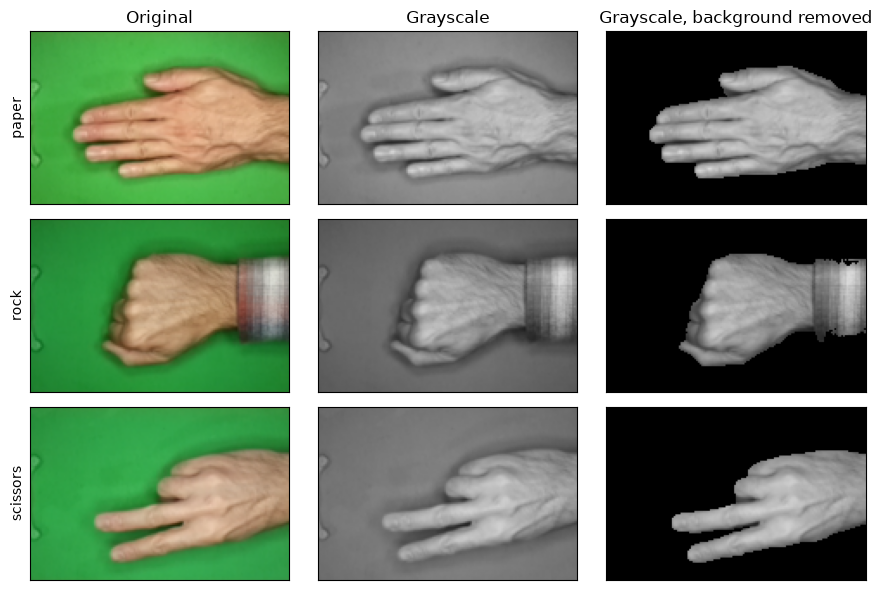

In [19]:
fig, ax = plt.subplots(3, 3, figsize=(9, 6))
for r, c in enumerate(CLASSES):
    i = np.where(y_train == r)[0][0]
    grigio = X_train[i, :, :, 0] * 0.299 + X_train[i, :, :, 1] * 0.587 + X_train[i, :, :, 2] * 0.114
    ax[r, 0].imshow(X_train[i])
    ax[r, 1].imshow(grigio, cmap='gray', vmin=0, vmax=255)
    ax[r, 2].imshow(grigio_senza_sfondo(X_train[i]), cmap='gray', vmin=0, vmax=255)
    ax[r, 0].set_ylabel(c)
ax[0, 0].set_title('Original')
ax[0, 1].set_title('Grayscale')
ax[0, 2].set_title('Grayscale, background removed')
for a in ax.ravel():
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.savefig(FIG_DIR + '/baseline_background_removal.png', dpi=150)
plt.show()

Rifaccio la PCA (200 componenti, solo sul train) sulle nuove feature e ripeto il tuning sul validation con le stesse griglie, aggiungendo n = 40 (il valore dell'autore) a tutti i modelli. Stessa regola per i pareggi.

In [20]:
pca_nb = PCA(n_components=200, svd_solver='full', random_state=SEED)
pca_nb.fit(G_train)
Zn_train = pca_nb.transform(G_train)
Zn_val = pca_nb.transform(G_val)
Zn_test = pca_nb.transform(G_test)

griglie_nb = {}
for nome in griglie:
    griglie_nb[nome] = (griglie[nome][0], [20, 40] + griglie[nome][1][1:], griglie[nome][2])
    print(nome, griglie_nb[nome][1])

LogReg [20, 40, 50, 100, 200]
kNN [20, 40, 50, 100]
SVM [20, 40, 50, 100]


In [21]:
righe = []
for nome in griglie_nb:
    nome_param, lista_n, lista_val = griglie_nb[nome]
    for n in lista_n:
        for v in lista_val:
            m = crea_modello(nome, v)
            m.fit(Zn_train[:, :n], y_train)
            p = m.predict(Zn_val[:, :n])
            righe.append([nome, n, nome_param, v, accuracy_score(y_val, p), f1_score(y_val, p, average='macro')])

val_nb = pd.DataFrame(righe, columns=['model', 'n_components', 'param_name', 'param_value', 'val_accuracy', 'val_macro_f1'])
val_nb['features'] = 'gray_no_background'
val_tutto = pd.concat([val, val_nb], ignore_index=True)
val_tutto.to_csv(MET_DIR + '/baseline_validation.csv', index=False)
print(len(val_nb), 'nuove configurazioni;', len(val_tutto), 'righe totali nel csv')

migliori_nb = {}
for nome in griglie_nb:
    sub = val_nb[val_nb['model'] == nome]
    best_f1 = -1
    for i in range(len(sub)):
        r = sub.iloc[i]
        if r['val_macro_f1'] > best_f1:
            best_f1 = r['val_macro_f1']
            v = r['param_value']
            if nome == 'kNN':
                v = int(v)
            migliori_nb[nome] = (int(r['n_components']), v, r['val_accuracy'], r['val_macro_f1'])

for nome in migliori_nb:
    n, v, acc, f1 = migliori_nb[nome]
    print(nome, '-> n =', n, ',', griglie_nb[nome][0], '=', v, '| val accuracy', round(acc, 4), '| val macro-F1', round(f1, 4))

56 nuove configurazioni; 99 righe totali nel csv
LogReg -> n = 100 , C = 0.1 | val accuracy 0.8344 | val macro-F1 0.8341
kNN -> n = 100 , k = 1 | val accuracy 0.9755 | val macro-F1 0.9754
SVM -> n = 40 , C = 10.0 | val accuracy 0.9816 | val macro-F1 0.9816


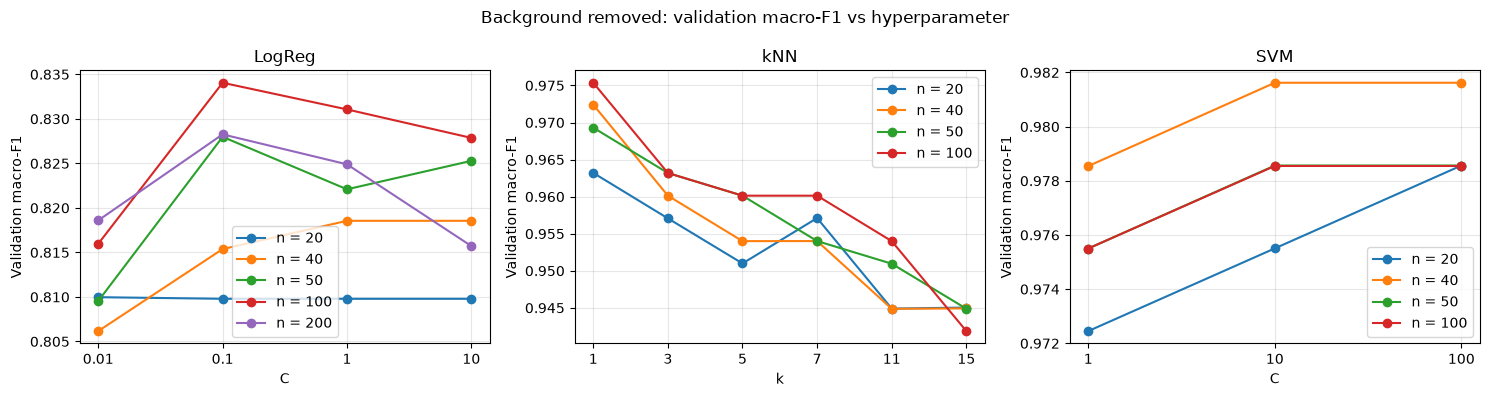

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j, nome in enumerate(griglie_nb):
    nome_param, lista_n, lista_val = griglie_nb[nome]
    for n in lista_n:
        sub = val_nb[(val_nb['model'] == nome) & (val_nb['n_components'] == n)]
        ax[j].plot(range(len(lista_val)), sub['val_macro_f1'], marker='o', label='n = ' + str(n))
    ax[j].set_xticks(range(len(lista_val)))
    ax[j].set_xticklabels(lista_val)
    ax[j].set_xlabel(nome_param)
    ax[j].set_ylabel('Validation macro-F1')
    ax[j].set_title(nome)
    ax[j].grid(alpha=0.3)
    ax[j].legend()
plt.suptitle('Background removed: validation macro-F1 vs hyperparameter')
plt.tight_layout()
plt.savefig(FIG_DIR + '/baseline_validation_nobg.png', dpi=150)
plt.show()

Test (usato una sola volta) per la migliore configurazione di ogni modello con lo sfondo rimosso.

In [23]:
righe_test = []
pred_test_nb = {}
for nome in migliori_nb:
    n, v = migliori_nb[nome][0], migliori_nb[nome][1]
    p, r = valuta_test(nome, crea_modello(nome, v), Zn_train[:, :n], Zn_test[:, :n])
    righe_test.append(r + [n, griglie_nb[nome][0], v])
    pred_test_nb[nome] = p

test_nb = pd.DataFrame(righe_test, columns=['model', 'test_accuracy', 'test_macro_f1', 'fit_time_s', 'pred_time_ms_per_image', 'n_components', 'param_name', 'param_value'])
test_nb['features'] = 'gray_no_background'
test_tutto = pd.concat([test, test_nb], ignore_index=True)
test_tutto.to_csv(MET_DIR + '/baseline_test.csv', index=False)

# confronto gray vs gray_no_background
confronto = []
for nome in migliori_nb:
    a = test[test['model'] == nome].iloc[0]
    b = test_nb[test_nb['model'] == nome].iloc[0]
    confronto.append([nome, a['test_accuracy'], b['test_accuracy'], a['test_macro_f1'], b['test_macro_f1']])
confronto = pd.DataFrame(confronto, columns=['model', 'acc_gray', 'acc_no_bg', 'f1_gray', 'f1_no_bg']).round(4)
confronto

,model,acc_gray,acc_no_bg,f1_gray,f1_no_bg
0,LogReg,0.6810,0.8436,0.6815,0.8437
1,kNN,0.8926,0.9755,0.8928,0.9753
2,SVM,0.9387,0.9877,0.9387,0.9877


In [24]:
best_nome_nb = None
best_f1 = -1
for nome in migliori_nb:
    if migliori_nb[nome][3] > best_f1:
        best_f1 = migliori_nb[nome][3]
        best_nome_nb = nome
print('Miglior modello con sfondo rimosso (validation):', best_nome_nb, '| prima:', best_nome)

pred_best_nb = pred_test_nb[best_nome_nb]
print(classification_report(y_test, pred_best_nb, target_names=CLASSES, digits=4))
print('Errori sul test:', int((pred_best_nb != y_test).sum()), 'su', len(y_test))

if best_nome_nb != best_nome:
    cm = confusion_matrix(y_test, pred_best_nb)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Test confusion matrix - ' + best_nome_nb + ' (background removed)')
    plt.tight_layout()
    plt.savefig(FIG_DIR + '/baseline_confusion_matrix_nobg.png', dpi=150)
    plt.show()
else:
    print('Il miglior modello non cambia: non salvo una seconda matrice di confusione.')

Miglior modello con sfondo rimosso (validation): SVM | prima: SVM
              precision    recall  f1-score   support

       paper     0.9811    0.9811    0.9811       106
        rock     1.0000    0.9907    0.9953       108
    scissors     0.9823    0.9911    0.9867       112

    accuracy                         0.9877       326
   macro avg     0.9878    0.9876    0.9877       326
weighted avg     0.9878    0.9877    0.9877       326

Errori sul test: 4 su 326
Il miglior modello non cambia: non salvo una seconda matrice di confusione.


### Interpretazione

Togliendo lo sfondo i risultati migliorano molto per tutti i modelli. Sul test il macro-F1 della SVM passa da 0.939 a 0.988 (4 errori su 326 invece di 20), quello del k-NN da 0.893 a 0.975 e quello della regressione logistica da 0.682 a 0.844. Con lo sfondo rimosso la SVM arriva sul test al livello dichiarato dall'autore (0.98-0.99), quindi questo passaggio di preprocessing spiega bene il divario che avevo visto (il tuning di gamma da solo non lo spiegava). Resta il fatto che il test è uno solo, con 326 immagini: la differenza tra 0.988 e 0.98 corrisponde a pochi errori.

Il trucco però funziona solo perché tutte le foto hanno lo stesso sfondo verde uniforme: è una regola fatta a mano (un "shortcut") sul colore dello sfondo, e non è detto che valga per foto nuove con sfondi diversi. Un altro sfondo verrebbe lasciato nell'immagine, o un oggetto verde verrebbe cancellato. Questa limitazione non l'ho ancora misurata: la testerò più avanti su foto nuove di mani (RQ3).

## 7. Esperimento sul leakage

Domanda: quanto si gonfia il punteggio se uso uno split casuale (che può mettere copie quasi identiche della stessa immagine sia in train che in test) invece dello split per gruppi di duplicati?

Per i seed da 0 a 4 faccio:
- split casuale stratificato 70/15/15 (prima 30% da parte, poi metà di questo);
- split per gruppi, con la **stessa funzione** usata in `02_split` (la copio qui), con lo stesso seed.

Per ogni split e per ognuno dei 3 modelli (con gli iperparametri migliori del punto 5) fitto la PCA solo sul train di quello split, fitto il modello e misuro il test. Il validation qui non serve.

In [25]:
def split_per_gruppi(df, test_size=0.15, val_size=0.15, seed=SEED):
    rng = np.random.default_rng(seed)
    split = pd.Series('train', index=df.index)
    for c in CLASSES:
        dfc = df[df['label'] == c]
        dim_gruppi = dfc['dup_group'].value_counts()
        gruppi = np.sort(dfc['dup_group'].unique())
        rng.shuffle(gruppi)
        n_test = test_size * len(dfc)
        n_val = val_size * len(dfc)
        conta_test, conta_val = 0, 0
        for g in gruppi:
            idx = dfc.index[dfc['dup_group'] == g]
            if conta_test + dim_gruppi[g] <= n_test:
                split[idx] = 'test'
                conta_test += dim_gruppi[g]
            elif conta_val + dim_gruppi[g] <= n_val:
                split[idx] = 'val'
                conta_val += dim_gruppi[g]
    return split

In [26]:
def split_casuale(seed):
    idx = np.arange(len(df))
    idx_train, idx_resto = train_test_split(idx, test_size=0.30, stratify=labels, random_state=seed)
    idx_val, idx_test = train_test_split(idx_resto, test_size=0.5, stratify=labels[idx_resto], random_state=seed)
    return idx_train, idx_test

def split_gruppi(seed):
    s = split_per_gruppi(df, seed=seed).to_numpy()
    return np.where(s == 'train')[0], np.where(s == 'test')[0]

# controllo: i gruppi sono davvero separati nello split per gruppi, mentre nel casuale no
dg = df['dup_group'].to_numpy()
for tipo, f in [('random', split_casuale), ('group', split_gruppi)]:
    itr, ite = f(0)
    condivisi = len(set(dg[itr]) & set(dg[ite]))
    print(tipo, 'seed 0: train', len(itr), ', test', len(ite), ', gruppi presenti sia in train che in test:', condivisi)

random seed 0: train 1531 , test 329 , gruppi presenti sia in train che in test: 44
group seed 0: train 1536 , test 326 , gruppi presenti sia in train che in test: 0


In [27]:
righe_leak = []
for seed in range(5):
    for tipo, f in [('random', split_casuale), ('group', split_gruppi)]:
        itr, ite = f(seed)
        # PCA solo sul train di questo split
        pca_s = PCA(n_components=200, svd_solver='full', random_state=SEED)
        pca_s.fit(F_all[itr])
        Ztr = pca_s.transform(F_all[itr])
        Zte = pca_s.transform(F_all[ite])
        for nome in migliori:
            n, v = migliori[nome][0], migliori[nome][1]
            m = crea_modello(nome, v)
            m.fit(Ztr[:, :n], y_all[itr])
            p = m.predict(Zte[:, :n])
            righe_leak.append([nome, tipo, seed, accuracy_score(y_all[ite], p), f1_score(y_all[ite], p, average='macro')])
    print('seed', seed, 'fatto')

leak = pd.DataFrame(righe_leak, columns=['model', 'split_type', 'seed', 'test_accuracy', 'test_macro_f1'])
leak.to_csv(MET_DIR + '/baseline_leakage.csv', index=False)
leak

seed 0 fatto


seed 1 fatto


seed 2 fatto


seed 3 fatto


seed 4 fatto


,model,split_type,seed,test_accuracy,test_macro_f1
0,LogReg,random,0,0.720365,0.720137
1,kNN,random,0,0.936170,0.936184
2,SVM,random,0,0.954407,0.954944
3,LogReg,group,0,0.674847,0.670518
4,kNN,group,0,0.895706,0.895371
5,SVM,group,0,0.941718,0.941832
6,LogReg,random,1,0.705167,0.706214
7,kNN,random,1,0.902736,0.902855
8,SVM,random,1,0.945289,0.945039
9,LogReg,group,1,0.708589,0.707508


In [28]:
riassunto = leak.groupby(['model', 'split_type'])[['test_accuracy', 'test_macro_f1']].agg(['mean', 'std']).round(4)
riassunto

test_accuracy         test_macro_f1        
                           mean     std          mean     std
model  split_type                                            
LogReg group             0.7006  0.0244        0.6994  0.0252
       random            0.7234  0.0147        0.7235  0.0145
SVM    group             0.9417  0.0038        0.9419  0.0039
       random            0.9380  0.0119        0.9380  0.0120
kNN    group             0.9141  0.0128        0.9140  0.0130
       random            0.9185  0.0120        0.9184  0.0120

In [29]:
# tabella differenza random - group per modello
for nome in migliori:
    a_r = leak[(leak['model'] == nome) & (leak['split_type'] == 'random')]['test_accuracy']
    a_g = leak[(leak['model'] == nome) & (leak['split_type'] == 'group')]['test_accuracy']
    print(nome, ': random', round(a_r.mean(), 4), '+-', round(a_r.std(), 4), '| group', round(a_g.mean(), 4), '+-', round(a_g.std(), 4), '| differenza', round(a_r.mean() - a_g.mean(), 4))

LogReg : random 0.7234 +- 0.0147 | group 0.7006 +- 0.0244 | differenza 0.0228
kNN : random 0.9185 +- 0.012 | group 0.9141 +- 0.0128 | differenza 0.0044
SVM : random 0.938 +- 0.0119 | group 0.9417 +- 0.0038 | differenza -0.0037


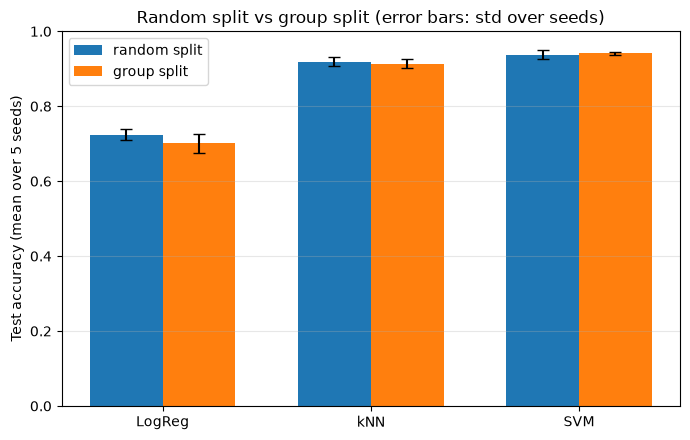

In [30]:
modelli = list(migliori.keys())
x = np.arange(len(modelli))
larghezza = 0.35
plt.figure(figsize=(7, 4.5))
for j, tipo in enumerate(['random', 'group']):
    medie = []
    stds = []
    for nome in modelli:
        a = leak[(leak['model'] == nome) & (leak['split_type'] == tipo)]['test_accuracy']
        medie.append(a.mean())
        stds.append(a.std())
    plt.bar(x + (j - 0.5) * larghezza, medie, larghezza, yerr=stds, capsize=4, label=tipo + ' split')
plt.xticks(x, modelli)
plt.ylabel('Test accuracy (mean over 5 seeds)')
plt.title('Random split vs group split (error bars: std over seeds)')
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR + '/baseline_leakage.png', dpi=150)
plt.show()

### Interpretazione

Con 5 seed la differenza tra split casuale e split per gruppi è piccola e non ha un segno coerente:
- LogReg: 0.723 ± 0.015 (casuale) contro 0.701 ± 0.024 (gruppi), differenza di circa +0.023, un po' più grande della deviazione standard ma con soli 5 seed non la considero solida;
- k-NN: 0.918 ± 0.012 contro 0.914 ± 0.013, differenza +0.004, dentro la variabilità tra seed;
- SVM: 0.938 ± 0.012 contro 0.942 ± 0.004, differenza -0.004 (al contrario, ma dentro la variabilità).

Quindi con questi modelli e questi dati non vedo un'inflazione evidente del punteggio dovuta ai duplicati. Il controllo sui gruppi conferma che lo split casuale mette gruppi di duplicati sia in train che in test (44 gruppi condivisi con seed 0), mentre quello per gruppi no, ma questo non si traduce in un vantaggio chiaro per i modelli classici. Una possibile spiegazione (ipotesi, non verificata) è che le feature PCA su pixel grigi siano poco sensibili a questi quasi-duplicati, o che i duplicati siano pochi rispetto al totale. Lo split per gruppi resta comunque la scelta corretta per il resto del progetto, perché evita il problema per costruzione. Il test set usato qui cambia con il seed, quindi i numeri non sono confrontabili punto a punto con la tabella del punto 6.

## Riepilogo

- Dummy (classe più frequente): accuracy 0.344 e macro-F1 0.170 sia sul validation che sul test.
- **Feature in grigio (75x50)**. Migliori configurazioni (macro-F1 di validation): LogReg n = 50, C = 1 (0.686); k-NN n = 100, k = 1 (0.914); SVM n = 100, C = 10 (0.948, pari a C = 100 ma scelgo il valore più semplice). Test: LogReg 0.681 / 0.682 (accuracy / macro-F1), k-NN 0.893 / 0.893, SVM 0.939 / 0.939 (20 errori su 326). Il tuning di gamma dell'SVM non migliora il risultato (gamma = 'scale' è il migliore).
- **Con sfondo rimosso** (replica dell'autore). Migliori configurazioni: LogReg n = 100, C = 0.1 (validation 0.834); k-NN n = 100, k = 1 (0.975); SVM n = 40, C = 10 (0.982). Test: LogReg 0.844 / 0.844, k-NN 0.975 / 0.975, SVM 0.988 / 0.988 (4 errori su 326). Il miglior modello resta la SVM e arriva al livello dichiarato dall'autore (0.98-0.99): il divario era dovuto al preprocessing.
- Il vantaggio dipende dal fatto che lo sfondo è sempre lo stesso verde uniforme: è uno shortcut costruito a mano che potrebbe non funzionare su sfondi diversi (da verificare con RQ3).
- Tempi: tutti i modelli si fittano in meno di 0.1 s sulle feature PCA (la PCA stessa è esclusa); la predizione per immagine costa circa 0.0003 ms (LogReg), 0.005 ms (k-NN) e 0.04 ms (SVM) nell'ultima esecuzione (variano un po' da run a run).
- Leakage (feature in grigio): la differenza tra split casuale e per gruppi è piccola e dentro la variabilità tra seed (accuracy media casuale/gruppi: LogReg 0.723/0.701, k-NN 0.918/0.914, SVM 0.938/0.942).
- La regressione logistica lineare sui pixel è debole (0.68 test in grigio, 0.84 senza sfondo): i metodi non lineari (SVM RBF, k-NN) funzionano molto meglio. La SVM senza sfondo è la soglia da battere con la CNN.